In [9]:
curve_table = pd.DataFrame({
    "Q": q_values,
    "expected_profit": means,
    "std_error": std_errors,
})
curve_table.to_csv(os.path.join(TABLES_DIR, "expected_profit_by_Q.csv"), index=False)

summary = pd.DataFrame([{
    "distribution": "Poisson(120)",
    "num_scenarios": len(demand),
    "stochastic_optimal_Q": q_star,
    "expected_profit_at_Q": round(result["best_profit"], 1),
    "std_error": round(result["best_se"], 1),
    "newsvendor_theory_Q": q_theory,
    "exact_optimal_Q": q_exact,
}])
summary.to_csv(os.path.join(TABLES_DIR, "stochastic_optimal_summary.csv"), index=False)
summary

NameError: name 'q_values' is not defined

## Module 08 summary
- Evaluated every integer Q from 0 to 500 on 10,000 Poisson(120) training scenarios.
- Stochastic-optimal Q* = 120, with estimated expected profit ₹76,196 (SE ₹94.8).
- Newsvendor check: Cu = ₹900, Co = ₹900, critical ratio = 0.5, so the optimum is the Poisson(120) median = 120. This matches the brute-force result.
- Exact calculation with the Poisson probabilities also gives Q = 120, with expected profit ₹76,139. The simulation differs by about ₹57, within one standard error.
- Expected profit falls by about ₹900 per unit beyond Q*, because each extra unit costs c + h = ₹900.
- Q* was chosen on training scenarios, so it is tested on independent scenarios in Module 10.

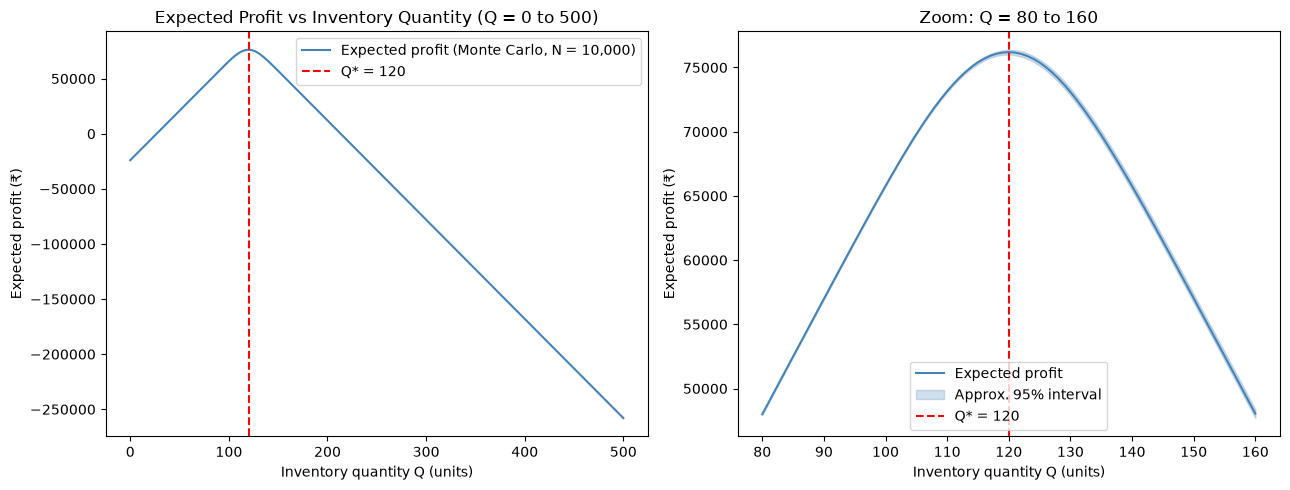

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: full range
axes[0].plot(q_values, means, color="steelblue", label="Expected profit (Monte Carlo, N = 10,000)")
axes[0].axvline(q_star, color="red", linestyle="--", label=f"Q* = {q_star}")
axes[0].set_title("Expected Profit vs Inventory Quantity (Q = 0 to 500)")
axes[0].set_xlabel("Inventory quantity Q (units)")
axes[0].set_ylabel("Expected profit (₹)")
axes[0].legend()

# Right: zoom near the optimum with 95% error band
zoom = (q_values >= 80) & (q_values <= 160)
axes[1].plot(q_values[zoom], means[zoom], color="steelblue", label="Expected profit")
axes[1].fill_between(q_values[zoom],
                     means[zoom] - 1.96 * std_errors[zoom],
                     means[zoom] + 1.96 * std_errors[zoom],
                     color="steelblue", alpha=0.25, label="Approx. 95% interval")
axes[1].axvline(q_star, color="red", linestyle="--", label=f"Q* = {q_star}")
axes[1].set_title("Zoom: Q = 80 to 160")
axes[1].set_xlabel("Inventory quantity Q (units)")
axes[1].set_ylabel("Expected profit (₹)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "03_inventory_vs_expected_profit.png"), dpi=200)
plt.show()

In [ ]:
d_grid = np.arange(0, 401)                         # demand values 0..400
pmf = stats.poisson.pmf(d_grid, MEAN_DEMAND)       # exact probabilities
print("Probability mass covered:", pmf.sum().round(8))

exact_profits = profit(q_values[:, None], d_grid[None, :], **COSTS) @ pmf
q_exact = int(q_values[np.argmax(exact_profits)])

print(f"Exact optimal Q                : {q_exact}")
print(f"Exact expected profit at Q     : ₹{exact_profits[q_exact]:,.0f}")
print(f"Exact expected profit at Q*    : ₹{exact_profits[q_star]:,.0f}")
print(f"Max gap |simulated - exact| over all Q: ₹{np.max(np.abs(means - exact_profits)):,.0f}")

Probability mass covered: 1.0
Exact optimal Q                : 120
Exact expected profit at Q     : ₹76,139
Exact expected profit at Q*    : ₹76,139
Max gap |simulated - exact| over all Q: ₹106


In [ ]:
Cu = COSTS["p"] - COSTS["c"] + COSTS["s"]     # underage cost per unit
Co = COSTS["c"] + COSTS["h"]                  # overage cost per unit
critical_ratio = Cu / (Cu + Co)
q_theory = int(stats.poisson.ppf(critical_ratio, MEAN_DEMAND))

print(f"Underage cost Cu = ₹{Cu}, overage cost Co = ₹{Co}")
print(f"Critical ratio Cu/(Cu+Co) = {critical_ratio:.3f}")
print(f"Theoretical Q (Poisson quantile at the ratio) = {q_theory}")
print(f"Brute-force Q* from simulation               = {q_star}")
print(f"Difference (units)                           = {q_star - q_theory}")

Underage cost Cu = ₹900, overage cost Co = ₹900
Critical ratio Cu/(Cu+Co) = 0.500
Theoretical Q (Poisson quantile at the ratio) = 120
Brute-force Q* from simulation               = 120
Difference (units)                           = 0


In [ ]:
q_star = result["best_q"]
lo, hi = max(q_star - 5, 0), min(q_star + 5, Q_MAX)

around = pd.DataFrame({
    "Q": q_values[lo:hi + 1],
    "expected_profit": means[lo:hi + 1].round(0),
    "std_error": std_errors[lo:hi + 1].round(1),
})
around

,Q,expected_profit,std_error
0,115,75406.0,66.7
1,116,75687.0,72.1
2,117,75910.0,77.7
3,118,76069.0,83.3
4,119,76162.0,89.1
5,120,76196.0,94.8
6,121,76159.0,100.5
7,122,76058.0,106.2
8,123,75896.0,111.7
9,124,75673.0,117.1


In [ ]:
result = find_optimal_q(demand, Q_MAX, **COSTS)

q_values = result["q_values"]
means = result["means"]
std_errors = result["std_errors"]

print("Number of Q values evaluated:", len(q_values))
print(f"Stochastic-optimal Q*          : {result['best_q']} units")
print(f"Expected profit at Q*          : ₹{result['best_profit']:,.0f}")
print(f"Standard error at Q*           : ₹{result['best_se']:,.1f}")

Number of Q values evaluated: 501
Stochastic-optimal Q*          : 120 units
Expected profit at Q*          : ₹76,196
Standard error at Q*           : ₹94.8


In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.append(os.path.abspath(".."))
from src.parameters import COSTS, Q_MAX, MEAN_DEMAND
from src.profit import profit
from src.optimization import expected_profit_curve, find_optimal_q

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")

df = pd.read_csv(os.path.join("..", "data", "processed", "synthetic_demand_clean.csv"))
demand = df["poisson"].to_numpy()      # training scenarios: Poisson(120), seed 42
print("Training scenarios:", len(demand), "| Q range: 0 to", Q_MAX)
print("Costs:", COSTS)

Training scenarios: 10000 | Q range: 0 to 500
Costs: {'p': 1500, 'c': 800, 'h': 100, 's': 200}
